# Lab 9: Hindi POS Tagging with MEMM and CRF

This notebook trains a Maximum Entropy Markov Model (MEMM) and a Conditional Random Field (CRF) on the supplied Hindi POS data. It evaluates both models alongside the Assignment 7 Naive Bayes and HMM baselines, reporting per-tag precision, recall, F1, accuracy, and comparison charts on the dev and test splits.

Run the cells from top to bottom. Training uses the full training split and may take some time.

## Implementation notes

- The Naive Bayes and HMM functions are imported from [`Lab 7/pos_baselines.py`](../Lab%207/pos_baselines.py), which contains the reusable Assignment 7 implementations.
- The referenced [nltk-maxent-pos-tagger](https://github.com/arne-cl/nltk-maxent-pos-tagger) uses NLTK's Maximum Entropy classifier. Its original tagger source targets Python 2, so the MEMM below uses the supported NLTK `MaxentClassifier` API with a first-order previous-tag feature and greedy decoding.
- CRF word features follow the assignment specification exactly: prefixes/suffixes of lengths 1–4 (or `NULL` when too short), previous/current/next words, and a `LESS`/`MORE` length feature.

In [1]:
%pip install nltk sklearn-crfsuite

  Using cached sklearn_crfsuite-0.5.0-py2.py3-none-any.whl.metadata (4.9 kB)
  Using cached python_crfsuite-0.9.12-cp313-cp313-win_amd64.whl.metadata (4.4 kB)
  Using cached tabulate-0.10.0-py3-none-any.whl.metadata (40 kB)
Using cached sklearn_crfsuite-0.5.0-py2.py3-none-any.whl (10 kB)
Using cached python_crfsuite-0.9.12-cp313-cp313-win_amd64.whl (303 kB)
Using cached tabulate-0.10.0-py3-none-any.whl (39 kB)

   ---------------------------------------- 0/3 [tabulate]
   ---------------------------------------- 0/3 [tabulate]
   ------------- -------------------------- 1/3 [python-crfsuite]
   -------------------------- ------------- 2/3 [sklearn-crfsuite]
   ---------------------------------------- 3/3 [sklearn-crfsuite]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
import pandas as pd
import sklearn_crfsuite
from IPython.display import display
from nltk.classify import MaxentClassifier

WORKSPACE_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "Lab 9" / "Hindi-POS-Data").is_dir()),
    None,
)
if WORKSPACE_ROOT is None:
    raise FileNotFoundError("Could not find Lab 9/Hindi-POS-Data from the notebook's working directory.")

LAB9_DIR = WORKSPACE_ROOT / "Lab 9"
LAB7_DIR = WORKSPACE_ROOT / "Lab 7"
OUTPUT_DIR = LAB9_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(LAB7_DIR))
from pos_baselines import (
    BOS,
    EOS,
    evaluate_by_tag,
    forward_viterbi,
    load_tagged_sentences,
    predict_naive_bayes,
    train_hmm,
    train_naive_bayes,
)

def word_features(words, index):
    word = words[index]
    features = {
        "previous_word": words[index - 1] if index > 0 else BOS,
        "current_word": word,
        "next_word": words[index + 1] if index + 1 < len(words) else EOS,
        "length_feature": "LESS" if len(word) <= 4 else "MORE",
    }
    for length in range(1, 5):
        features[f"prefix_{length}"] = word[:length] if len(word) >= length else "NULL"
        features[f"suffix_{length}"] = word[-length:] if len(word) >= length else "NULL"
    return features

print(f"Workspace: {WORKSPACE_ROOT}")
print(f"Lab 9 data: {LAB9_DIR / 'Hindi-POS-Data'}")

Workspace: e:\STUDY\NLP
Lab 9 data: e:\STUDY\NLP\Lab 9\Hindi-POS-Data


## 1. Load and check the Hindi data

Each non-empty line contains a Hindi word and POS tag separated by a tab. Blank lines mark sentence boundaries.

In [6]:
DATA_DIR = LAB9_DIR / "Hindi-POS-Data"
train_sentences = load_tagged_sentences(DATA_DIR / "hindi-train-pos.txt")
dev_sentences = load_tagged_sentences(DATA_DIR / "hindi-dev-pos.txt")
test_sentences = load_tagged_sentences(DATA_DIR / "hindi-test-pos.txt")

tags = sorted({tag for sentence in train_sentences for _, tag in sentence})
for split_name, split in (("dev", dev_sentences), ("test", test_sentences)):
    split_tags = {tag for sentence in split for _, tag in sentence}
    unknown_tags = split_tags.difference(tags)
    if unknown_tags:
        raise ValueError(f"{split_name} contains tags absent from training: {sorted(unknown_tags)}")

data_summary = pd.DataFrame(
    [
        {
            "split": name,
            "sentences": len(split),
            "tokens": sum(len(sentence) for sentence in split),
        }
        for name, split in (
            ("train", train_sentences),
            ("dev", dev_sentences),
            ("test", test_sentences),
        )
    ]
)
display(data_summary)
print(f"Training tags: {len(tags)}")

,split,sentences,tokens
0,train,15087,325710
1,dev,1866,40762
2,test,1910,41415


Training tags: 24


## 2. Train Assignment 7 baselines

The baseline APIs use tagged sentences in the form `[(word, tag), ...]`. HMM predictions use the forward Viterbi decoder from Assignment 7.

In [7]:
naive_bayes_model = train_naive_bayes(train_sentences, tags)
hmm_model = train_hmm(train_sentences, tags)
print("Naive Bayes and HMM baselines trained.")

Naive Bayes and HMM baselines trained.


## 3. MEMM features and training

The MEMM conditions each tag on the current word context and the previously predicted tag. During training, the previous gold tag is used; at inference, decoding is greedy from left to right.

In [8]:
def memm_features(words, index, previous_tag):
    features = word_features(words, index).copy()
    features["previous_tag"] = previous_tag
    return features


def train_memm(sentences, label_set, max_iter=20, count_cutoff=2):
    training_examples = []
    for sentence in sentences:
        words = [word for word, _ in sentence]
        previous_tag = BOS
        for index, (_, gold_tag) in enumerate(sentence):
            training_examples.append(
                (memm_features(words, index, previous_tag), gold_tag)
            )
            previous_tag = gold_tag

    return MaxentClassifier.train(
        training_examples,
        algorithm="gis",
        trace=1,
        labels=label_set,
        max_iter=max_iter,
        count_cutoff=count_cutoff,
    )


def predict_memm(words, classifier):
    predictions = []
    previous_tag = BOS
    for index in range(len(words)):
        predicted_tag = classifier.classify(
            memm_features(words, index, previous_tag)
        )
        predictions.append(predicted_tag)
        previous_tag = predicted_tag
    return predictions


MAXENT_MAX_ITER = 20
MAXENT_COUNT_CUTOFF = 2
start_time = time.time()
memm_model = train_memm(
    train_sentences,
    tags,
    max_iter=MAXENT_MAX_ITER,
    count_cutoff=MAXENT_COUNT_CUTOFF,
)
print(f"MEMM trained in {(time.time() - start_time) / 60:.1f} minutes.")

  ==> Training (20 iterations)
MEMM trained in 115.0 minutes.


## 4. CRF features and training

The feature function is applied independently to each token in a sentence. `NULL` is used when a word is shorter than a requested prefix or suffix length.

In [9]:
def sentence_features(sentence):
    words = [word for word, _ in sentence]
    return [word_features(words, index) for index in range(len(words))]


def sentence_labels(sentence):
    return [tag for _, tag in sentence]


feature_example = word_features(["अ", "जाना", "विद्यालय"], 0)
assert feature_example["prefix_3"] == "NULL"
assert feature_example["suffix_4"] == "NULL"
assert feature_example["length_feature"] == "LESS"
print(feature_example)

{'previous_word': '<BOS>', 'current_word': 'अ', 'next_word': 'जाना', 'length_feature': 'LESS', 'prefix_1': 'अ', 'suffix_1': 'अ', 'prefix_2': 'NULL', 'suffix_2': 'NULL', 'prefix_3': 'NULL', 'suffix_3': 'NULL', 'prefix_4': 'NULL', 'suffix_4': 'NULL'}


In [10]:
X_train = [sentence_features(sentence) for sentence in train_sentences]
y_train = [sentence_labels(sentence) for sentence in train_sentences]

crf_model = sklearn_crfsuite.CRF(
    algorithm="lbfgs",
    c1=0.1,
    c2=0.1,
    max_iterations=100,
    all_possible_transitions=True,
    verbose=False,
)
start_time = time.time()
crf_model.fit(X_train, y_train)
del X_train, y_train
print(f"CRF trained in {(time.time() - start_time) / 60:.1f} minutes.")

CRF trained in 3.3 minutes.


## 5. Predict and evaluate

Per-tag precision, recall, and F1 use the same evaluation function as the Assignment 7 baselines. Accuracy and macro-F1 are summarized for each model and split.

Evaluating dev split...
Dev per-tag metrics


,tag,model,precision,recall,f1,support
0,CC_CCD,Naive Bayes,0.9557,0.9638,0.9598,829
1,CC_CCS,Naive Bayes,0.9311,0.9521,0.9415,752
2,DM_DMD,Naive Bayes,0.9332,0.8116,0.8682,499
3,JJ,Naive Bayes,0.8410,0.8435,0.8422,2370
4,N_NN,Naive Bayes,0.8928,0.8940,0.8934,9098
...,...,...,...,...,...,...
91,RP_INTF,CRF,0.8824,0.8824,0.8824,34
92,RP_NEG,CRF,0.9925,0.9925,0.9925,266
93,RP_RPD,CRF,0.9752,0.9737,0.9745,647
94,V_VAUX,CRF,0.9906,0.9898,0.9902,2544


Dev per-tag F1 comparison


model,CRF,HMM,MEMM,Naive Bayes
tag,,,,
CC_CCD,0.9880,0.9607,0.9796,0.9598
CC_CCS,0.9848,0.9554,0.9836,0.9415
DM_DMD,0.9683,0.8959,0.9345,0.8682
JJ,0.9257,0.8870,0.9165,0.8422
N_NN,0.9413,0.9147,0.9351,0.8934
N_NNP,0.8936,0.8384,0.8795,0.8286
N_NST,0.9936,0.9436,0.9855,0.9258
PR_PRF,1.0000,0.9935,0.9967,0.8614
PR_PRL,0.9573,0.8596,0.9626,0.5170


Dev overall summary


,accuracy,macro_f1
model,,
Naive Bayes,0.9102,0.7436
HMM,0.9305,0.9071
MEMM,0.9556,0.9542
CRF,0.9634,0.9649


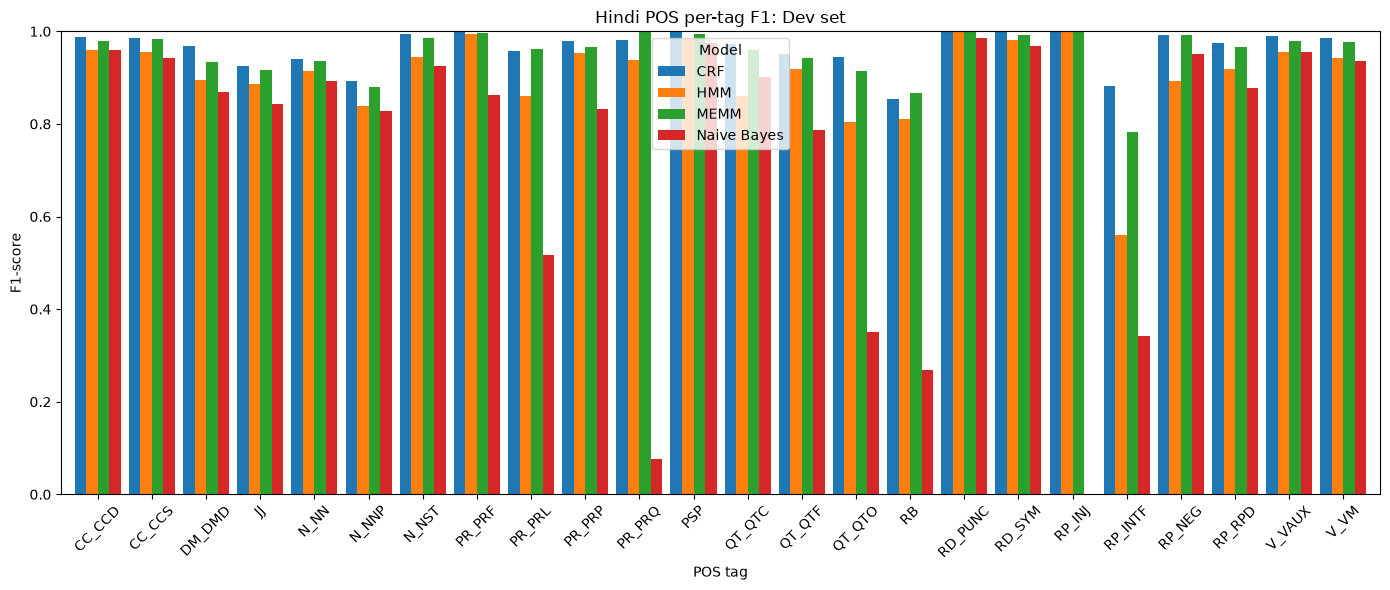

Evaluating test split...
Test per-tag metrics


,tag,model,precision,recall,f1,support
0,CC_CCD,Naive Bayes,0.9570,0.9806,0.9687,772
1,CC_CCS,Naive Bayes,0.9515,0.9592,0.9553,736
2,DM_DMD,Naive Bayes,0.9478,0.8798,0.9126,516
3,JJ,Naive Bayes,0.8347,0.8720,0.8529,2258
4,N_NN,Naive Bayes,0.8923,0.8789,0.8855,9303
...,...,...,...,...,...,...
91,RP_INTF,CRF,0.9000,0.9310,0.9153,29
92,RP_NEG,CRF,0.9918,1.0000,0.9959,243
93,RP_RPD,CRF,0.9784,0.9562,0.9672,617
94,V_VAUX,CRF,0.9894,0.9937,0.9915,2534


Test per-tag F1 comparison


model,CRF,HMM,MEMM,Naive Bayes
tag,,,,
CC_CCD,0.9865,0.9507,0.9846,0.9687
CC_CCS,0.9905,0.9526,0.9886,0.9553
DM_DMD,0.9722,0.8955,0.9377,0.9126
JJ,0.9242,0.8992,0.9246,0.8529
N_NN,0.9423,0.9072,0.9369,0.8855
N_NNP,0.9025,0.8411,0.8970,0.8274
N_NST,0.9896,0.9316,0.9856,0.9286
PR_PRF,1.0000,0.9967,1.0000,0.8832
PR_PRL,0.9609,0.8350,0.9508,0.5323


Test overall summary


,accuracy,macro_f1
model,,
Naive Bayes,0.9104,0.7600
HMM,0.9285,0.8675
MEMM,0.9587,0.9180
CRF,0.9645,0.9288


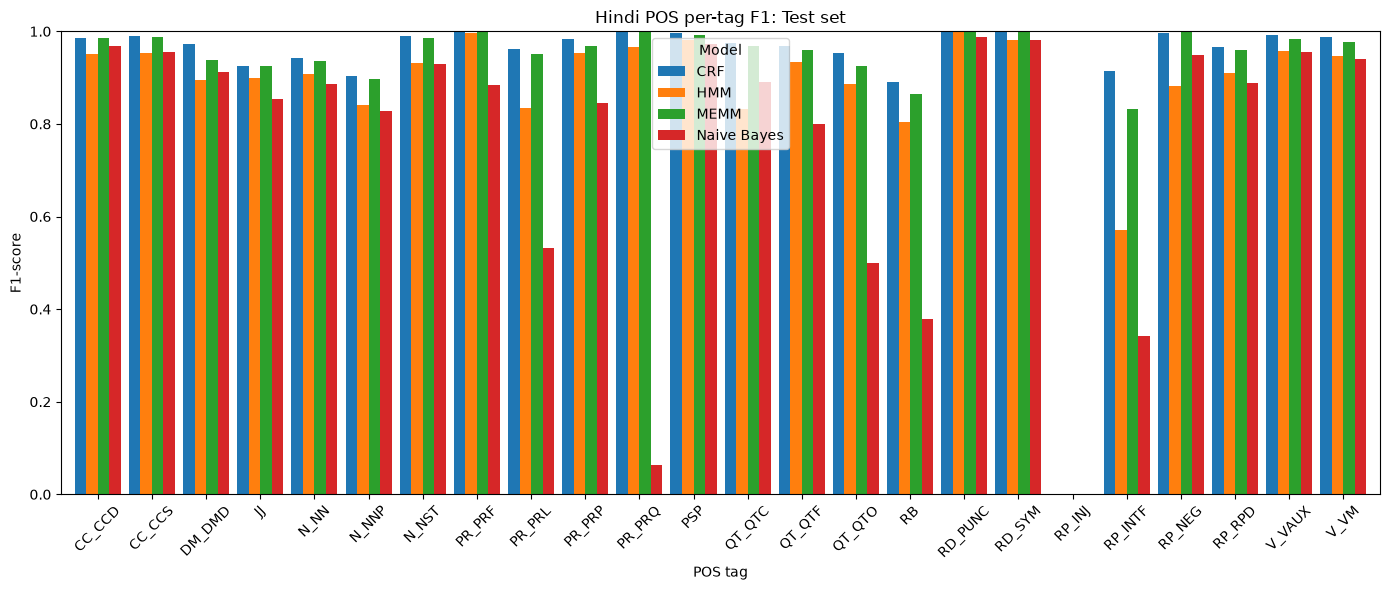

accuracy         macro_f1        
split            dev    test      dev    test
model                                        
CRF           0.9634  0.9645   0.9649  0.9288
HMM           0.9305  0.9285   0.9071  0.8675
MEMM          0.9556  0.9587   0.9542  0.9180
Naive Bayes   0.9102  0.9104   0.7436  0.7600

Saved comparison tables and charts to: e:\STUDY\NLP\Lab 9\outputs


In [14]:
def predict_all_models(sentences):
    words_by_sentence = [
        [word for word, _ in sentence] for sentence in sentences
    ]
    return {
        "Naive Bayes": [
            predict_naive_bayes(words, naive_bayes_model)
            for words in words_by_sentence
        ],
        "HMM": [forward_viterbi(words, hmm_model) for words in words_by_sentence],
        "MEMM": [predict_memm(words, memm_model) for words in words_by_sentence],
        "CRF": crf_model.predict(
            [
                [word_features(words, index) for index in range(len(words))]
                for words in words_by_sentence
            ]
        ),
    }


evaluation = {}
summary_rows = []
for split_name, split_sentences in (("dev", dev_sentences), ("test", test_sentences)):
    print(f"Evaluating {split_name} split...")
    split_predictions = predict_all_models(split_sentences)
    metric_tables = []
    model_summary = []

    for model_name, predictions in split_predictions.items():
        metrics, accuracy = evaluate_by_tag(split_sentences, predictions, tags)
        metrics.insert(1, "model", model_name)
        metric_tables.append(metrics)
        model_summary.append(
            {
                "model": model_name,
                "accuracy": accuracy,
                "macro_f1": metrics["f1"].mean(),
            }
        )
        summary_rows.append(
            {
                "split": split_name,
                "model": model_name,
                "accuracy": accuracy,
                "macro_f1": metrics["f1"].mean(),
            }
        )

    evaluation[split_name] = pd.concat(metric_tables, ignore_index=True)
    evaluation[split_name].to_csv(
        OUTPUT_DIR / f"pos_metrics_{split_name}.csv",
        index=False,
        encoding="utf-8-sig",
    )
    f1_comparison = evaluation[split_name].pivot(
        index="tag", columns="model", values="f1"
    )
    f1_comparison.to_csv(
        OUTPUT_DIR / f"pos_f1_comparison_{split_name}.csv",
        encoding="utf-8-sig",
    )
    print(f"{split_name.title()} per-tag metrics")
    display(evaluation[split_name].round(4))
    print(f"{split_name.title()} per-tag F1 comparison")
    display(
        evaluation[split_name]
        .pivot(index="tag", columns="model", values="f1")
        .round(4)
    )
    print(f"{split_name.title()} overall summary")
    display(pd.DataFrame(model_summary).set_index("model").round(4))

    axis = f1_comparison.plot(kind="bar", figsize=(14, 6), width=0.85)
    axis.set(
        title=f"Hindi POS per-tag F1: {split_name.title()} set",
        xlabel="POS tag",
        ylabel="F1-score",
        ylim=(0, 1),
    )
    axis.legend(title="Model")
    axis.tick_params(axis="x", labelrotation=45)
    axis.figure.tight_layout()
    axis.figure.savefig(
        OUTPUT_DIR / f"pos_f1_comparison_{split_name}.png",
        dpi=160,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(axis.figure)

summary = pd.DataFrame(summary_rows)
summary.to_csv(
    OUTPUT_DIR / "pos_model_summary.csv",
    index=False,
    encoding="utf-8-sig",
)
display(summary.pivot(index="model", columns="split", values=["accuracy", "macro_f1"]).round(4))
print(f"Saved comparison tables and charts to: {OUTPUT_DIR}")


## 6. Comparative study

The detailed metric tables and grouped bar charts above compare the four models tag-by-tag on both held-out splits. Review per-tag support together with F1, since rare tags can have less reliable scores.

The notebook saves its generated deliverables to `Lab 9/outputs/`: full per-tag precision/recall/F1/support tables, per-tag F1 comparison tables, dev/test charts, and an overall accuracy/macro-F1 summary table.